# Wobble Coordinates

J2000 coordinates of the wobble pointings (N, S, E, W) around a source, using the same convention as `heap.toy_events.wobble_pointings()`:
each pointing is `WOBBLE` deg from the source along a great circle at position angle N = 0, E = 90, S = 180, W = 270 deg (east of north).
N/S are Dec +/- `WOBBLE`; E/W are offset along the sky, so their RA changes by about `WOBBLE` / cos(Dec) and their Dec drops very slightly.

The plots follow `example_notebooks/significance_testing.ipynb`, east left and north up as on the sky:
- star: the source
- `+`: each wobble pointing
- dotted: the circle `WOBBLE` deg from the source
- dashed: each pointing's camera edge

## Imports

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import astropy.units as u
from astropy.coordinates import FK5

from heap import significance as sg
from heap import toy_events as toy
from heap.parameterize import CAMERA_HALF_WIDTH
from heap.sources import SOURCES

## Settings

In [2]:
SOURCE_NAME = "Crab" # a heap.sources.SOURCES name
WOBBLE = 0.5 # wobble offset (deg)
DIRECTIONS = ("N", "S", "E", "W") # keys of toy.WOBBLE_ANGLES
COLORS = {"N": "tab:blue", "S": "tab:orange", "E": "tab:green", "W": "tab:red"}

J2000 = FK5(equinox="J2000")
source = SOURCES[SOURCE_NAME].transform_to(J2000)
pointings = toy.wobble_pointings(source, WOBBLE, DIRECTIONS)

## Coordinates

In [3]:
def wobble_table(sources):
    """
    The source and its wobble pointings, one row each, indexed by (source, direction).

    Parameters:
        sources: {name: SkyCoord}

    Returns:
        DataFrame with RA/Dec (J2000) as hms/dms strings and in deg, and each pointing's separation and
        position angle (deg, east of north) from the source
    """
    rows = []
    for name, coord in sources.items():
        c = coord.transform_to(J2000)
        for d, p in {"on source": c, **toy.wobble_pointings(c, WOBBLE, DIRECTIONS)}.items():
            rows.append({
                "source": name, "direction": d,
                "RA (hms)": p.ra.to_string(u.hour, sep="hms", precision=2, pad=True),
                "Dec (dms)": p.dec.to_string(u.deg, sep="dms", precision=1, alwayssign=True, pad=True),
                "RA (deg)": p.ra.deg, "Dec (deg)": p.dec.deg,
                "sep (deg)": c.separation(p).deg,
                "PA (deg)": np.nan if d == "source" else np.round(c.position_angle(p).deg, 1) % 360, # % 360: N rounds to 360.0 otherwise
            })
    return pd.DataFrame(rows).set_index(["source", "direction"])


def show(table):
    """table, formatted for display."""
    formats = {"RA (deg)": "{:.4f}", "Dec (deg)": "{:+.4f}", "sep (deg)": "{:.3f}", "PA (deg)": "{:.1f}"}
    return table.style.format(formats, na_rep="").set_caption(f"{WOBBLE} deg wobbles (J2000)")


show(wobble_table({SOURCE_NAME: SOURCES[SOURCE_NAME]}))

Every catalog source, for reference:

In [4]:
show(wobble_table(SOURCES))

## Plots

Left: the wobble pointings in RA/DEC, like `heap.significance.plot_sky_map()` (RA increasing to the left), with the aspect set to
1 / cos(Dec) so distances on the sky look the same in both directions.

Right: each pointing's camera in map coordinates (deg from the source, +x east, +y south, axes reversed for east left, north up),
like the region plots in `significance_testing.ipynb`.

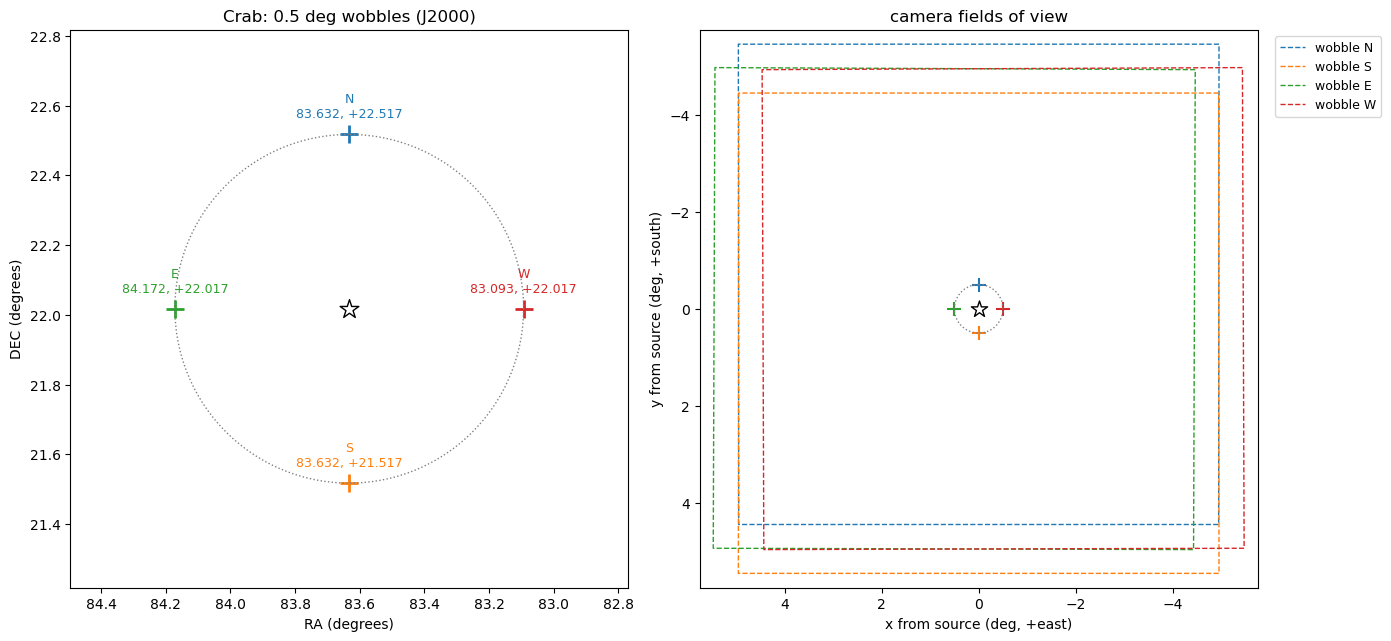

In [5]:
map_wcs = sg.make_wcs(source) # map coordinates: deg from the source, +x east, +y south
MAP_HALF_WIDTH = CAMERA_HALF_WIDTH + WOBBLE + 0.3 # every pointing's whole camera, with a margin


def to_map(w, x, y):
    """Camera (x, y) of the pointing with WCS w -> map coordinates."""
    return map_wcs.wcs_world2pix(*w.wcs_pix2world(x, y, 1), 1)


fig, (ax_sky, ax_cam) = plt.subplots(1, 2, figsize=(14, 6.5))

# RA/DEC
circle = source.directional_offset_by(np.linspace(0, 360, 361)*u.deg, WOBBLE*u.deg)
ax_sky.plot(circle.ra.deg, circle.dec.deg, color="grey", lw=1, ls=":")
for d, p in pointings.items():
    ax_sky.scatter(p.ra.deg, p.dec.deg, marker="+", color=COLORS[d], s=150, lw=2)
    ax_sky.annotate(f"{d}\n{p.ra.deg:.3f}, {p.dec.deg:+.3f}", (p.ra.deg, p.dec.deg), xytext=(0, 10), textcoords="offset points",
                    ha="center", va="bottom", color=COLORS[d], fontsize=9)
ax_sky.scatter(source.ra.deg, source.dec.deg, marker="*", facecolor="white", edgecolor="k", s=200, zorder=3)
pad = 1.6*WOBBLE
cos_dec = np.cos(source.dec.rad)
ax_sky.set_xlim(source.ra.deg + pad/cos_dec, source.ra.deg - pad/cos_dec) # RA increasing to the left (east)
ax_sky.set_ylim(source.dec.deg - pad, source.dec.deg + pad)
ax_sky.set_aspect(1/cos_dec)
ax_sky.set(xlabel="RA (degrees)", ylabel="DEC (degrees)", title=f"{SOURCE_NAME}: {WOBBLE} deg wobbles (J2000)")

# cameras in map coordinates
edge = np.linspace(-CAMERA_HALF_WIDTH, CAMERA_HALF_WIDTH, 50)
side = np.full_like(edge, CAMERA_HALF_WIDTH)
ring_x, ring_y = map_wcs.wcs_world2pix(circle.ra.deg, circle.dec.deg, 1)
ax_cam.plot(ring_x, ring_y, color="grey", lw=1, ls=":")
for d, p in pointings.items():
    w = sg.make_wcs(p)
    ax_cam.plot(*to_map(w, np.r_[edge, side, edge[::-1], -side], np.r_[-side, edge, side, edge[::-1]]), color=COLORS[d], lw=1, ls="--", label=f"wobble {d}")
    ax_cam.scatter(*to_map(w, 0, 0), marker="+", color=COLORS[d], s=100)
ax_cam.scatter(0, 0, marker="*", facecolor="white", edgecolor="k", s=150, zorder=3)
ax_cam.set_xlim(MAP_HALF_WIDTH, -MAP_HALF_WIDTH) # +x is east and +y south: reversed for east left, north up
ax_cam.set_ylim(MAP_HALF_WIDTH, -MAP_HALF_WIDTH)
ax_cam.set_aspect("equal")
ax_cam.set(xlabel="x from source (deg, +east)", ylabel="y from source (deg, +south)", title="camera fields of view")
ax_cam.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
plt.tight_layout()